<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\M Nawfal\AppData\Local\Temp\ipykernel_2104\1439595606.py:13: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
C:\Users\M Nawfal\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training model...


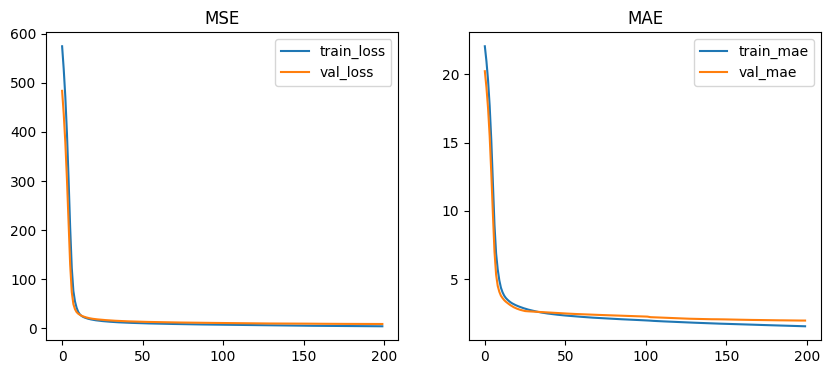

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

RMSE: 3.0258244172215067


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error

# Load dataset Boston Housing dari URL karena scikit-learn sudah menghapusnya di versi terbaru
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
y = raw_df.values[1::2, 2]

# Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(learning_rate=1e-3), loss='mse', metrics=['mae'])

# Train
print("Training model...")
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# Plot hasil
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE')

plt.subplot(1,2,2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')
plt.show()

pred = model.predict(X_val)
print('\nRMSE:', np.sqrt(mean_squared_error(y_val, pred)))

## Tugas 4
- Ubah learning rate.
- Bandingkan hasil loss.

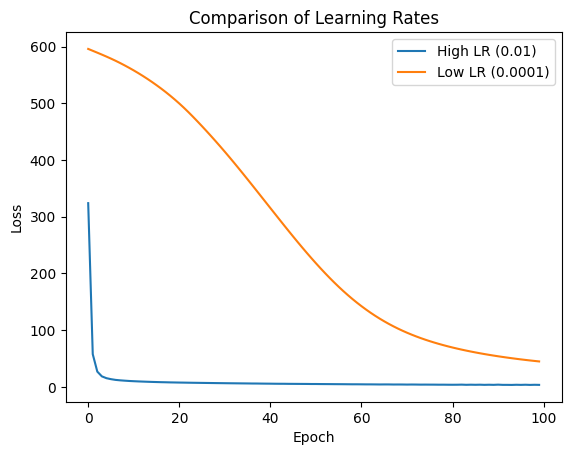

In [4]:
# Eksperimen dengan Learning Rate 0.01 (Lebih Tinggi)
model_high_lr = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model_high_lr.compile(optimizer=Adam(learning_rate=0.01), loss='mse')
h_high = model_high_lr.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=32, verbose=0)

# Eksperimen dengan Learning Rate 0.0001 (Lebih Rendah)
model_low_lr = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model_low_lr.compile(optimizer=Adam(learning_rate=0.0001), loss='mse')
h_low = model_low_lr.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100, batch_size=32, verbose=0)

plt.plot(h_high.history['loss'], label='High LR (0.01)')
plt.plot(h_low.history['loss'], label='Low LR (0.0001)')
plt.title('Comparison of Learning Rates')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()